# Olist E-commerce Sales Intelligence — Module 1

**Goal:** practise data inspection, cleaning, transformation, feature engineering, EDA, and visualization.

Work in small steps. Run one cell at a time, inspect outputs, and write down decisions. This notebook intentionally does not contain the final findings.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

!pip install plotly
import plotly.express as px


In [3]:
#here .. mean (while reading the CSV file), read csv locate above the folder, locate above the notebook folder, that is Data folder

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")

In [4]:
#Inspecting the Data to anlayze the NULL values and also get count of total Missing Values!

for name, df in {"orders": orders, "items":items, "products":products, "customers": customers}.items():
    print(f"{name}: rows, columns -> {df.shape}")
    # display(df.head())
    # display(df.info())
    print(f"\nMissing values in {name}:\n")
    display(df.isna().sum())
    print()
    total_missing_values = df.isna().sum().sum()
    print(f"Total missing values in {name}: {total_missing_values}")
    print("\n")


orders: rows, columns -> (99441, 8)

Missing values in orders:



order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


Total missing values in orders: 4908


items: rows, columns -> (112650, 7)

Missing values in items:



order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


Total missing values in items: 0


products: rows, columns -> (32951, 9)

Missing values in products:



product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


Total missing values in products: 2448


customers: rows, columns -> (99441, 5)

Missing values in customers:



customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64


Total missing values in customers: 0




In [5]:
#converting text format of Date in Order Dataset to the Date Format
date_cols = ["order_purchase_timestamp", "order_approved_at",
"order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce") #COERCE covert invalid date and time in to NaT(Not a time) to avoid stop of program 

In [6]:
orders[date_cols].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [7]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [8]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [9]:
missing_delivery = (
    orders.groupby("order_status")["order_delivered_customer_date"]
    .apply(lambda col: col.isna().sum())
)

display(missing_delivery)

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64

In [10]:
print("Duplicate order rows:", orders.duplicated().sum())
print("Duplicate item rows:", items.duplicated().sum())
print("Unique order IDs:", orders["order_id"].nunique())
print("Unique item order IDs:", items["order_id"].nunique())

Duplicate order rows: 0
Duplicate item rows: 0
Unique order IDs: 99441
Unique item order IDs: 98666


In [11]:
print("Price summary:")
display(items["price"].describe())
print("\n")

print("Freight summary:")
display(items["freight_value"].describe())
print()

print("Zero prices:", (items["price"] == 0).sum())
print("Negative prices:", (items["price"] < 0).sum())
print()

print("Zero freight:", (items["freight_value"] == 0).sum())
print("Negative freight:", (items["freight_value"] < 0).sum())

Price summary:


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64



Freight summary:


count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64


Zero prices: 0
Negative prices: 0

Zero freight: 383
Negative freight: 0


In [12]:
approval_before_purchase = (orders["order_approved_at"].notna() & (orders["order_approved_at"]<orders["order_purchase_timestamp"]))
print("Order approval Before Purchase")
print(approval_before_purchase.sum()) #return boolean value

Order approval Before Purchase
0


In [13]:
display(products["product_category_name"].dropna().unique()[:30])

<StringArray>
[                       'perfumaria',                             'artes',
                     'esporte_lazer',                             'bebes',
             'utilidades_domesticas',             'instrumentos_musicais',
                        'cool_stuff',                  'moveis_decoracao',
                  'eletrodomesticos',                        'brinquedos',
                   'cama_mesa_banho',  'construcao_ferramentas_seguranca',
            'informatica_acessorios',                      'beleza_saude',
                  'malas_acessorios',                'ferramentas_jardim',
                 'moveis_escritorio',                        'automotivo',
                       'eletronicos',                  'fashion_calcados',
                         'telefonia',                         'papelaria',
       'fashion_bolsas_e_acessorios',                               'pcs',
                   'casa_construcao',                'relogios_presentes',
 'construca

In [14]:
category = products["product_category_name"].dropna()

print(
    "Categories with surrounding whitespace:",
    (category != category.str.strip()).sum()
)

Categories with surrounding whitespace: 0


In [15]:
print(
    "Duplicate order-item keys:",
    items.duplicated(subset=["order_id", "order_item_id"]).sum()
)

Duplicate order-item keys: 0


In [16]:
carrier_before_purchase = (
    orders["order_delivered_carrier_date"].notna()
    & orders["order_purchase_timestamp"].notna()
    & (
        orders["order_delivered_carrier_date"]
        < orders["order_purchase_timestamp"]
    )
)

print("Carrier handoff before purchase:", carrier_before_purchase.sum())

Carrier handoff before purchase: 166


In [17]:
delivery_before_carrier = (
    orders["order_delivered_customer_date"].notna()
    & orders["order_delivered_carrier_date"].notna()
    & (
        orders["order_delivered_customer_date"]
        < orders["order_delivered_carrier_date"]
    )
)

print("Delivery before carrier handoff:", delivery_before_carrier.sum())

Delivery before carrier handoff: 23


In [18]:
delivery_before_purchase = (
    orders["order_delivered_customer_date"].notna()
    & orders["order_purchase_timestamp"].notna()
    & (
        orders["order_delivered_customer_date"]
        < orders["order_purchase_timestamp"]
    )
)

print("Delivery before purchase:", delivery_before_purchase.sum())

Delivery before purchase: 0


In [19]:
# Inspect zero or negative price records
display(
    items.loc[
        items["price"] <= 0,
        ["order_id", "order_item_id", "product_id", "price"]
    ].head(20)
)

# Inspect zero or negative freight records
display(
    items.loc[
        items["freight_value"] <= 0,
        ["order_id", "order_item_id", "product_id", "freight_value"]
    ].head(20)
)

,order_id,order_item_id,product_id,price


,order_id,order_item_id,product_id,freight_value
114,00404fa7a687c8c44ca69d42695aae73,1,53b36df67ebb7c41585e8d54d6772e08,0.0
258,00a870c6c06346e85335524935c600c0,1,aca2eb7d00ea1a7b8ebd4e68314663af,0.0
483,011c899816ea29773525bd3322dbb6aa,1,53b36df67ebb7c41585e8d54d6772e08,0.0
508,012b3f6ab7776a8ab3443a4ad7bef2e6,1,422879e10f46682990de24d770e7f83d,0.0
509,012b3f6ab7776a8ab3443a4ad7bef2e6,2,422879e10f46682990de24d770e7f83d,0.0
1784,04105b54650921ca3246f52e6f175f46,1,aca2eb7d00ea1a7b8ebd4e68314663af,0.0
2232,0517a3e68dac3308995edca2144db36e,1,53b36df67ebb7c41585e8d54d6772e08,0.0
2714,061ba2e2d7544790b6ed6b5b4dd9278c,1,53b36df67ebb7c41585e8d54d6772e08,0.0
3224,07441f525824bc6b31d4dc19c5d49fc9,1,53b36df67ebb7c41585e8d54d6772e08,0.0
3378,079f16689c29acb6cab92978e6af2137,1,aca2eb7d00ea1a7b8ebd4e68314663af,0.0


In [20]:
# Inspect customer delivery before carrier handoff
display(
    orders.loc[
        delivery_before_carrier,
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ].head(10)
)

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-20 11:20:52,2017-07-21 06:43:14,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-02 20:58:43,2017-07-02 21:10:20,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-16 12:35:34,2017-07-18 06:03:50,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-07-20 20:58:05,2017-07-22 11:45:11,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-18 11:48:20,2017-07-18 12:03:29,2017-07-20 23:03:42,2017-07-20 18:52:41
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-08 15:36:50,2016-10-08 18:13:44,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-14 20:17:04,2017-06-14 20:30:08,2017-06-27 14:51:54,2017-06-26 15:45:35
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-07 21:35:22,2017-08-08 21:45:15,2017-08-10 18:28:56,2017-08-10 18:05:38
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-07-26 11:46:34,2017-07-27 10:10:16,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-07-30 19:32:23,2017-07-30 19:45:09,2017-08-09 18:18:43,2017-08-01 21:13:01


In [21]:
orders_clean = orders.copy()
items_clean = items.copy()
products_clean = products.copy()
customers_clean = customers.copy()

#Verifying the copies with the original loaded Data set
print("Original orders:", orders.shape)
print("Cleaned orders:", orders_clean.shape)

print("Original items:", items.shape)
print("Cleaned items:", items_clean.shape)

print("Original products:", products.shape)
print("Cleaned products:", products_clean.shape)

print("Original customers:", customers.shape)
print("Cleaned customers:", customers_clean.shape)

Original orders: (99441, 8)
Cleaned orders: (99441, 8)
Original items: (112650, 7)
Cleaned items: (112650, 7)
Original products: (32951, 9)
Cleaned products: (32951, 9)
Original customers: (99441, 5)
Cleaned customers: (99441, 5)


In [22]:
category = products_clean["product_category_name"].dropna()

print(
    "Categories with surrounding whitespace:",
    (category != category.str.strip()).sum()
)

Categories with surrounding whitespace: 0


In [23]:
#Before making relationship first we have to check whether it has unique values or not 

print("Unique product IDs:", products_clean["product_id"].is_unique)
print("Unique order IDs:", orders_clean["order_id"].is_unique)
print("Unique customer IDs:", customers_clean["customer_id"].is_unique)

Unique product IDs: True
Unique order IDs: True
Unique customer IDs: True


In [24]:
#Join item_clean and product_clean based on Product_id(unique)
items_products = items_clean.merge(products_clean, on='product_id', how='left', validate='many_to_one')


In [25]:
print("Shape:", items_products.shape)
display(items_products.head())

Shape: (112650, 15)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0


In [26]:
items_customers = items_products.merge(
    orders_clean[
        [
            "order_id",
            "customer_id",
            "order_status",
            "order_purchase_timestamp"
        ]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

In [27]:
print("Shape:", items_customers.shape)
display(items_customers.head())

Shape: (112650, 18)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,customer_id,order_status,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51


In [28]:
items_customers = items_customers.merge(
    customers_clean[
        ["customer_id", "customer_state", "customer_city"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

In [29]:
print("Shape:", items_customers.shape)
display(items_customers.head())

Shape: (112650, 20)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,customer_id,order_status,order_purchase_timestamp,customer_state,customer_city
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,RJ,campos dos goytacazes
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,SP,santa fe do sul
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,MG,para de minas
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,SP,atibaia
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,SP,varzea paulista


In [30]:
print("Missing product category:", items_customers["product_category_name"].isna().sum())

print("Missing order status:", items_customers["order_status"].isna().sum())

print("Missing customer IDs:", items_customers["customer_id"].isna().sum())

print("Misiing Order ID:", items_customers["order_id"].isna().sum())

print("Misiing Product ID:", items_customers["product_id"].isna().sum())



Missing product category: 1603
Missing order status: 0
Missing customer IDs: 0
Misiing Order ID: 0
Misiing Product ID: 0


In [31]:
#Suppose one product has a missing category but appears in 5 different orders. The product dataset counts it once, while the joined item-level table counts it 5 times.

unmatched_products = ~items_clean["product_id"].isin(products_clean["product_id"])

print("Item rows without a matching product:", unmatched_products.sum())
print("Missing categories in products dataset:", products_clean["product_category_name"].isna().sum())

Item rows without a matching product: 0
Missing categories in products dataset: 610


In [32]:
print(
    "Unique products with missing categories:",
    items_customers.loc[
        items_customers["product_category_name"].isna(),
        "product_id"
    ].nunique()
)

Unique products with missing categories: 610


In [33]:
items_customers["order_month"] = (
    items_customers["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

display(
    items_customers[
        ["order_purchase_timestamp", "order_month"]
    ].head()
)

,order_purchase_timestamp,order_month
0,2017-09-13 08:59:02,2017-09
1,2017-04-26 10:53:06,2017-04
2,2018-01-14 14:33:31,2018-01
3,2018-08-08 10:00:35,2018-08
4,2017-02-04 13:57:51,2017-02


In [34]:
#According to your handbook, item_revenue represents the item price only, excluding freight.

items_customers["item_revenue"] = items_customers["price"]

display(
    items_customers[["price", "item_revenue"]].head()
)

,price,item_revenue
0,58.90,58.90
1,239.90,239.90
2,199.00,199.00
3,12.99,12.99
4,199.90,199.90


In [35]:
#This column represents item price plus freight charges.
items_customers["item_plus_freight"] = (
    items_customers["price"] + items_customers["freight_value"]
)

display(
    items_customers[
        ["price", "freight_value", "item_plus_freight"]
    ].head()
)

,price,freight_value,item_plus_freight
0,58.90,13.29,72.19
1,239.90,19.93,259.83
2,199.00,17.87,216.87
3,12.99,12.79,25.78
4,199.90,18.14,218.04


In [36]:
#Newly Created table by left join i.e, items_customers table 

print("Final table shape:", items_customers.shape)

display(
    items_customers[
        [
            "order_id",
            "product_id",
            "order_month",
            "price",
            "freight_value",
            "item_revenue",
            "item_plus_freight"
        ]
    ].head()
)

Final table shape: (112650, 23)


,order_id,product_id,order_month,price,freight_value,item_revenue,item_plus_freight
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,2017-09,58.90,13.29,58.90,72.19
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,2017-04,239.90,19.93,239.90,259.83
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,2018-01,199.00,17.87,199.00,216.87
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,2018-08,12.99,12.79,12.99,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,2017-02,199.90,18.14,199.90,218.04


In [37]:
print("Unique orders:", items_customers["order_id"].nunique())

print("Unique products:", items_customers["product_id"].nunique())


Unique orders: 98666
Unique products: 32951


In [38]:
#Before and afer Joining the table 

print("Orders before joins:", items_clean["order_id"].nunique())
print("Orders after joins:", items_customers["order_id"].nunique())
print('\n')
print("Products before joins:", items_clean["product_id"].nunique())
print("Products after joins:", items_customers["product_id"].nunique())

Orders before joins: 98666
Orders after joins: 98666


Products before joins: 32951
Products after joins: 32951


In [39]:
print("Total item revenue:", items_customers["item_revenue"].sum())

Total item revenue: 13591643.7


In [40]:
order_revenue = (
    items_customers.groupby("order_id")["item_revenue"].sum()
)

print("Number of aggregated orders:", len(order_revenue))
print("Total order revenue:", order_revenue.sum())

Number of aggregated orders: 98666
Total order revenue: 13591643.7


In [41]:
product_revenue = (
    items_customers.groupby("product_id")["item_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="item_revenue", ascending=False)
)

display(product_revenue.head(10))

,product_id,item_revenue
24086,bb50f2e236e5eea0100680137654686c,63885.00
14068,6cdd53843498f92890544667809f1595,54730.20
27613,d6160fb7873f184099d9bc95e30376af,48899.34
27039,d1c427060a0f73f6b889a5c7c61f2ac4,47214.51
19742,99a4788cb24856965c36a24e339b6058,43025.56
8051,3dd2a17168ec895c781a9191c1e95ad7,41082.60
4996,25c38557cf793876c5abdd5931f922db,38907.32
12351,5f504b3a1c75b73d6151be81eb05bdc9,37733.90
10867,53b36df67ebb7c41585e8d54d6772e08,37683.42
22112,aca2eb7d00ea1a7b8ebd4e68314663af,37608.90


In [42]:
product_id = "bb50f2e236e5eea0100680137654686c"

product_revenue = items_customers.loc[
    items_customers["product_id"] == product_id,
    "item_revenue"
].sum()

print("Product ID:", product_id)
print("Total Revenue:", product_revenue)

Product ID: bb50f2e236e5eea0100680137654686c
Total Revenue: 63885.0


In [43]:
order_revenue = (
    items_customers.groupby("order_id")["item_revenue"]
    .sum()
    .reset_index()
)

print("Number of orders:", len(order_revenue))
print("Total item revenue:", order_revenue["item_revenue"].sum())

Number of orders: 98666
Total item revenue: 13591643.7


In [44]:


delivered_orders = orders_clean.loc[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].notna())
].copy()

print("Delivered orders:", delivered_orders.shape)

display(delivered_orders.head())

Delivered orders: (96470, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [45]:
#Delivery timestamp − Purchase timestamp	Calculates the time difference
#.dt.total_seconds()	Converts the time difference into seconds
#Why 86,400? Because one day contains 24 × 60 × 60 seconds.

delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivered_orders["delivery_days"]= (delivered_orders["delivery_days"].astype(int)) #Float Days in to Int days 

display(
    delivered_orders[
        ["order_id", "order_purchase_timestamp",
         "order_delivered_customer_date", "delivery_days"]
    ].head()
)

,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,8
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,13
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,9
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,13
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2


In [46]:
delivered_orders["late_delivery"] = (
    delivered_orders["order_delivered_customer_date"] >
    delivered_orders["order_estimated_delivery_date"]
)

print(delivered_orders["late_delivery"].value_counts())

late_delivery
False    88644
True      7826
Name: count, dtype: int64


In [47]:
late_percentage = delivered_orders["late_delivery"].mean() * 100

print(f"Late Delivery Percentage: {late_percentage:.2f}%")

Late Delivery Percentage: 8.11%


In [48]:
delivered_orders["order_estimated_delivery_date"].isna().sum()

np.int64(0)

In [49]:
delivered_orders["delivery_days"].describe()

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64

In [50]:
max_delivery_days = delivered_orders.loc[
    delivered_orders["delivery_days"] > 30
]
max_delivery_days.shape[0]

display(max_delivery_days[
    ["order_id", "delivery_days"]
].head())

,order_id,delivery_days
41,6ea2f835b4556291ffdc53fa0b3b95e8,33
97,6a0a8bfbbe700284feb0845d95e0867f,36
110,9d531c565e28c3e0d756192f84d8731f,56
115,8fc207e94fa91a7649c5a5dab690272a,54
252,f31535f21d145b2345e2bf7f09d62322,81


In [51]:
long_delivery_percentage = (
    max_delivery_days.shape[0] / delivered_orders.shape[0]
) * 100
print(f"Long delivery percentage: {long_delivery_percentage:.2f}%")

Long delivery percentage: 4.27%


In [52]:
monthly_sales = (
    items_customers.groupby("order_month", as_index=False)
    .agg(
        item_sales_value=("price", "sum"),
        items_sold=("order_item_id", "count")
    )
)


In [53]:
monthly_sales.head(5)

,order_month,item_sales_value,items_sold
0,2016-09,267.36,6
1,2016-10,49507.66,363
2,2016-12,10.90,1
3,2017-01,120312.87,955
4,2017-02,247303.02,1951


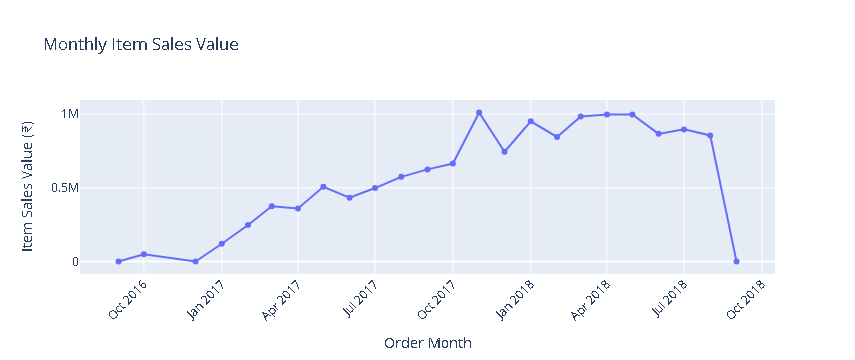

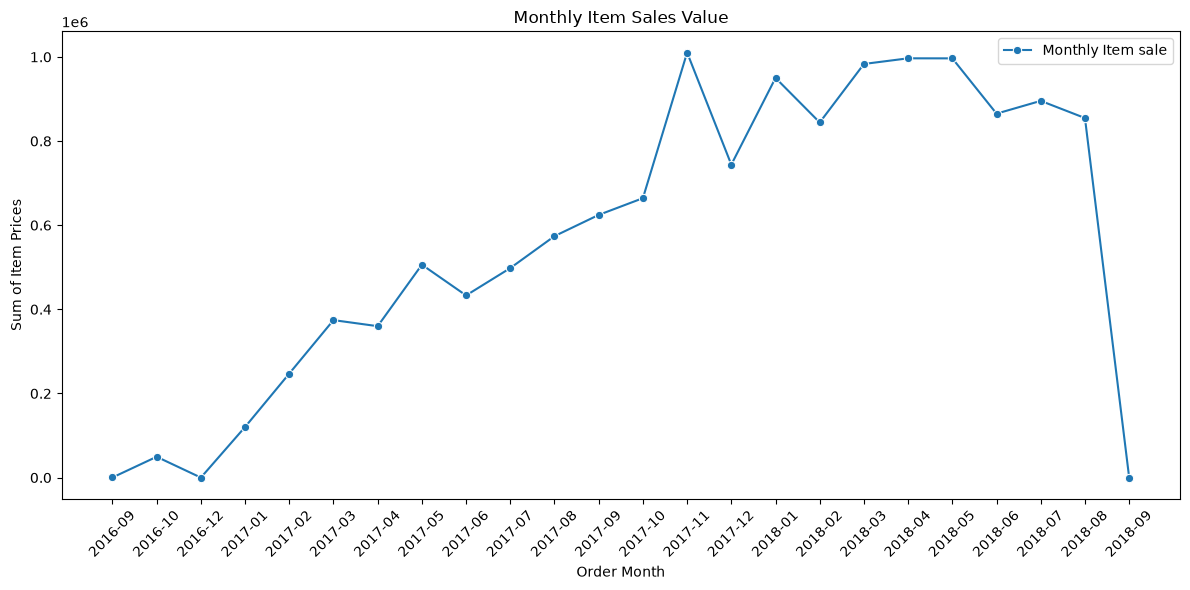

In [58]:
fig = px.line(
    monthly_sales,
    x="order_month",
    y="item_sales_value",
    markers=True,
    title="Monthly Item Sales Value",
    labels={
        "order_month": "Order Month",
        "item_sales_value": "Item Sales Value (₹)"
    },
    hover_data={
        "items_sold": True,
        "item_sales_value": ":,.2f"
    }
)

fig.update_layout(
    xaxis_tickangle=-45,
    hovermode="x unified"
)

fig.show()


plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_sales,
    x="order_month",
    y="item_sales_value",
    marker="o", label="Monthly Item sale"
)
plt.legend()
plt.xticks(rotation=45)
plt.title("Monthly Item Sales Value")
plt.xlabel("Order Month")
plt.ylabel("Sum of Item Prices")

plt.tight_layout()
plt.show()

In [60]:
top_categories = (
    items_customers.groupby("product_category_name", as_index=False)
    .agg(
        total_item_sales_value=("item_revenue", "sum")
    )
)


top_categories = top_categories.nlargest(
    10, "total_item_sales_value"
)
top_categories

,product_category_name,total_item_sales_value
11,beleza_saude,1258681.34
66,relogios_presentes,1205005.68
13,cama_mesa_banho,1036988.68
32,esporte_lazer,988048.97
44,informatica_acessorios,911954.32
54,moveis_decoracao,729762.49
26,cool_stuff,635290.85
72,utilidades_domesticas,632248.66
8,automotivo,592720.11
40,ferramentas_jardim,485256.46


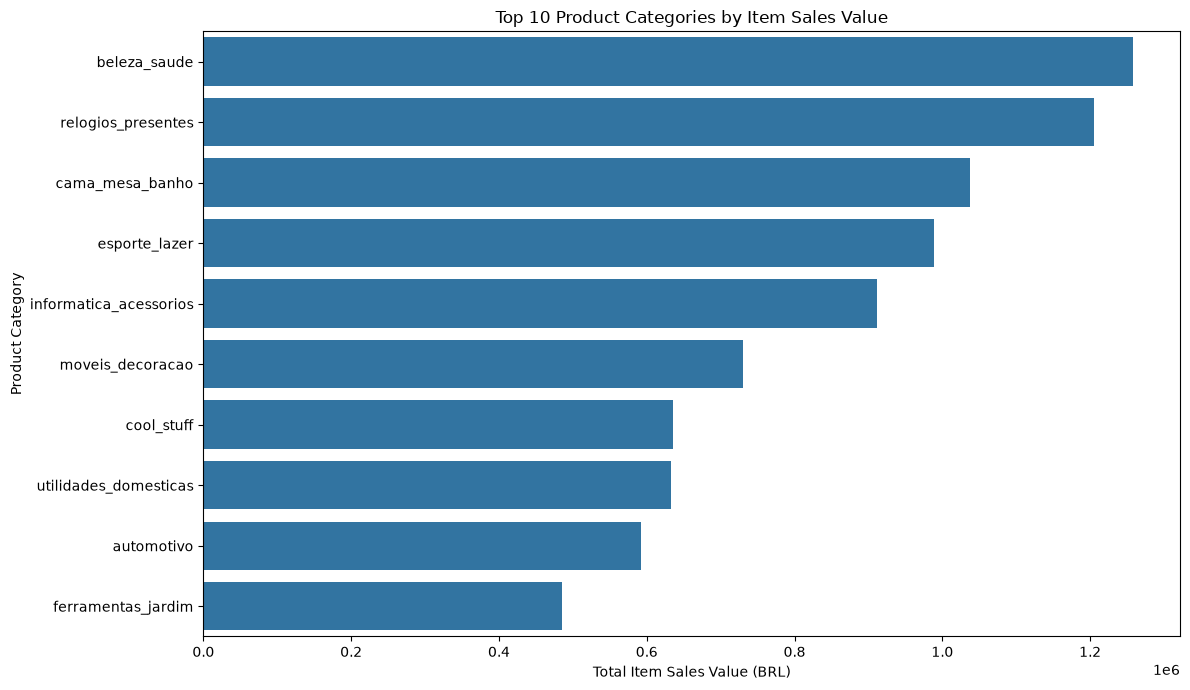

In [61]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_categories,
    x="total_item_sales_value",
    y="product_category_name"
)

plt.title("Top 10 Product Categories by Item Sales Value")
plt.xlabel("Total Item Sales Value (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

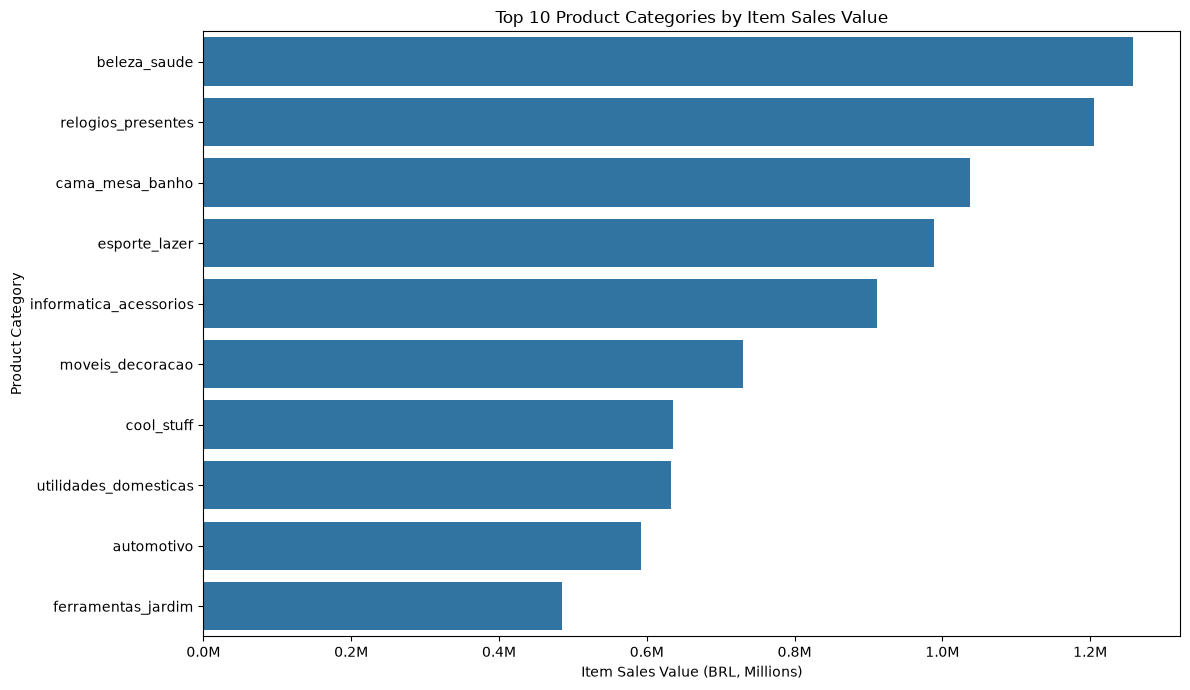

In [62]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_categories,
    x="total_item_sales_value",
    y="product_category_name"
)

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x/1_000_000:.1f}M")
)

plt.title("Top 10 Product Categories by Item Sales Value")
plt.xlabel("Item Sales Value (BRL, Millions)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [63]:
state_orders = orders_clean.merge(
    customers_clean[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

In [65]:
orders_by_state = (
    state_orders.groupby("customer_state")
    ["order_id"]
    .nunique()
    .reset_index(name="total_orders")
    .sort_values("total_orders", ascending=False)
)
orders_by_state

,customer_state,total_orders
25,SP,41746
18,RJ,12852
10,MG,11635
22,RS,5466
17,PR,5045
23,SC,3637
4,BA,3380
6,DF,2140
7,ES,2033
8,GO,2020


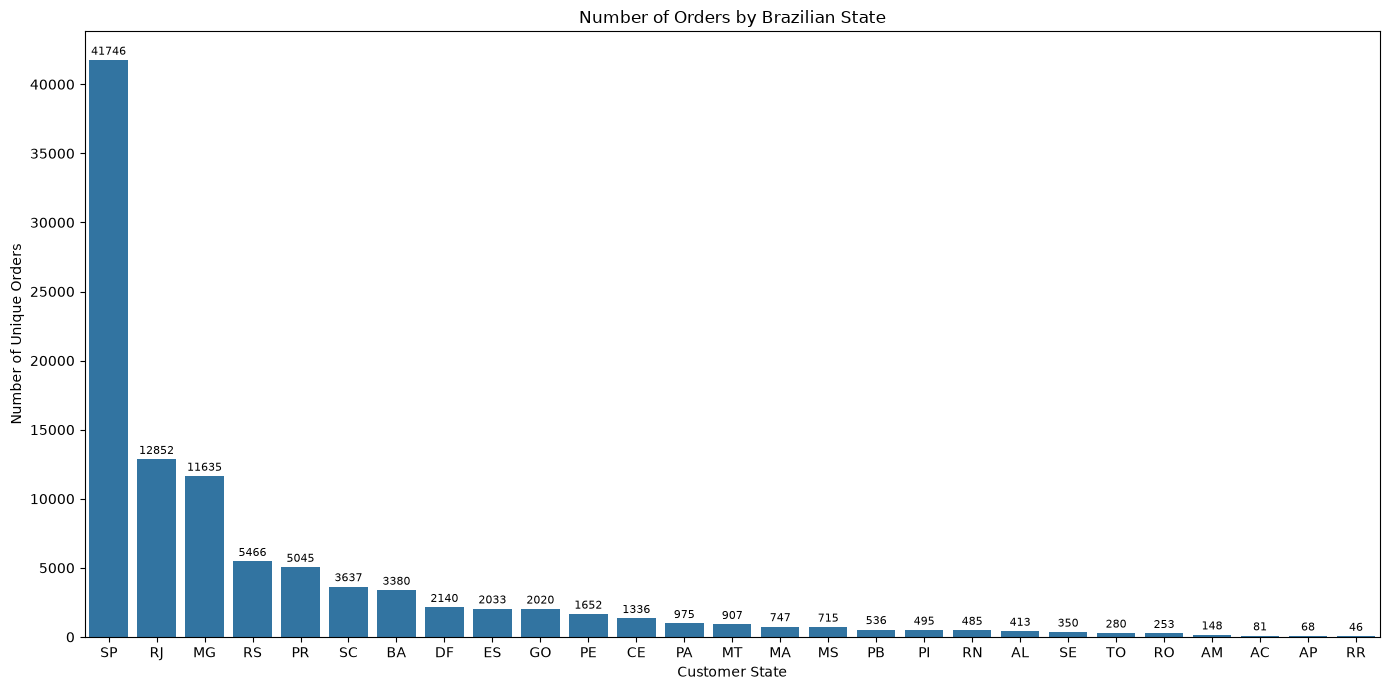

In [67]:
# NOTE: Vertical
# sns.barplot(data=df, x="category", y="value")

# # Horizontal
# sns.barplot(data=df, x="value", y="category")



plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=orders_by_state,
    x="customer_state",
    y="total_orders"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2, fontsize=8)

plt.title("Number of Orders by Brazilian State")
plt.xlabel("Customer State")
plt.ylabel("Number of Unique Orders")

plt.tight_layout()
plt.show()

In [68]:
delivered_orders["delivery_days"].describe()

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64

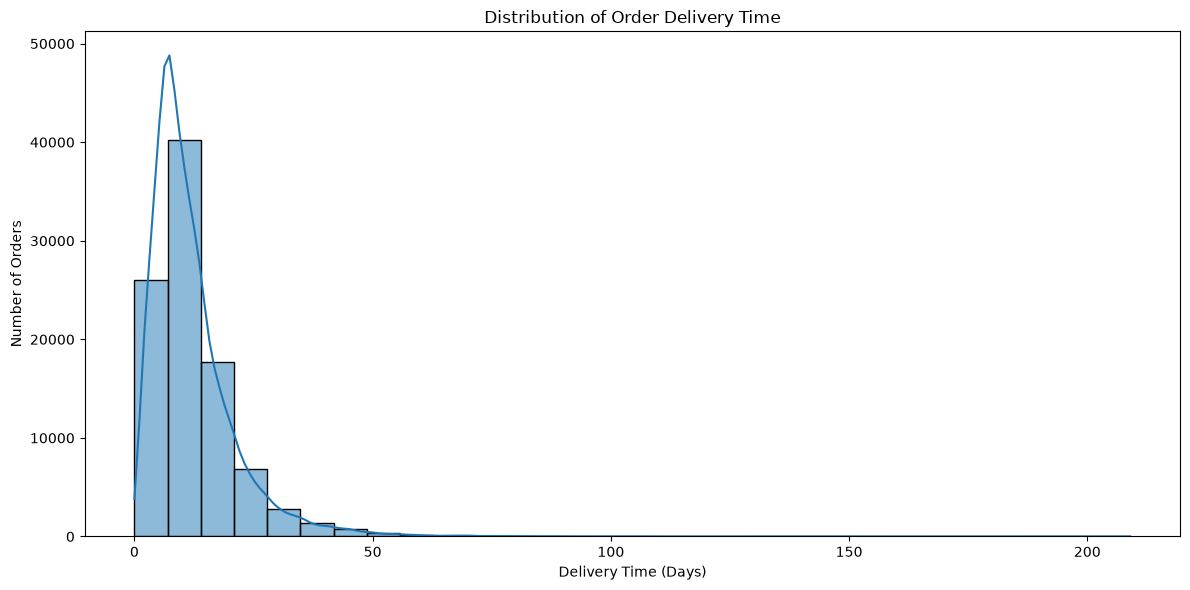

In [69]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=delivered_orders,
    x="delivery_days",
    bins=30,
    kde=True
)

plt.title("Distribution of Order Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

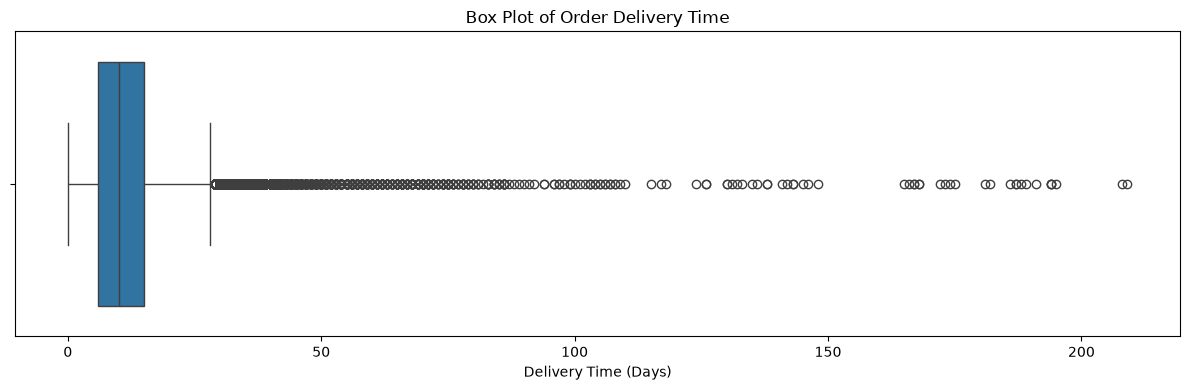

In [70]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    data=delivered_orders,
    x="delivery_days"
)

plt.title("Box Plot of Order Delivery Time")
plt.xlabel("Delivery Time (Days)")

plt.tight_layout()
plt.show()

In [71]:
late_delivery_percentage = (
    delivered_orders["late_delivery"].mean() * 100
)

print(
    "Late Delivery Percentage:",
    round(late_delivery_percentage, 2), "%"
)

Late Delivery Percentage: 8.11 %


In [72]:
# Calculate delivery status counts
delivery_status_counts = (
    delivered_orders["late_delivery"]
    .value_counts()
    .rename(index={False: "On Time", True: "Late"})
    .reset_index()
)

delivery_status_counts.columns = ["delivery_status", "order_count"]

# Calculate percentages
delivery_status_counts["percentage"] = (
    delivery_status_counts["order_count"] /
    delivery_status_counts["order_count"].sum()
) * 100

delivery_status_counts

,delivery_status,order_count,percentage
0,On Time,88644,91.887633
1,Late,7826,8.112367


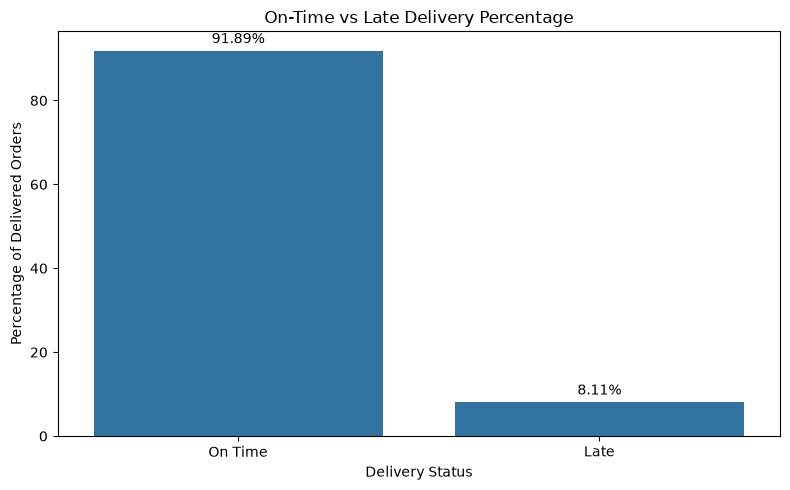

In [73]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=delivery_status_counts,
    x="delivery_status",
    y="percentage"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("On-Time vs Late Delivery Percentage")
plt.xlabel("Delivery Status")
plt.ylabel("Percentage of Delivered Orders")

plt.tight_layout()
plt.show()

In [74]:
# Highest item sales month
monthly_sales.nlargest(5, "item_sales_value")

,order_month,item_sales_value,items_sold
13,2017-11,1010271.37,8665
18,2018-04,996647.75,7975
19,2018-05,996517.68,7925
17,2018-03,983213.44,8217
15,2018-01,950030.36,8208


In [75]:
# Lowest item sales month
monthly_sales.nsmallest(5, "item_sales_value")

,order_month,item_sales_value,items_sold
2,2016-12,10.90,1
23,2018-09,145.00,1
0,2016-09,267.36,6
1,2016-10,49507.66,363
3,2017-01,120312.87,955


In [76]:
print("First purchase date:")
print(orders_clean["order_purchase_timestamp"].min())

print("\nLast purchase date:")
print(orders_clean["order_purchase_timestamp"].max())

First purchase date:
2016-09-04 21:15:19

Last purchase date:
2018-10-17 17:30:18


In [77]:
monthly_sales.head(3)

,order_month,item_sales_value,items_sold
0,2016-09,267.36,6
1,2016-10,49507.66,363
2,2016-12,10.90,1


In [78]:
monthly_sales.tail(3)

,order_month,item_sales_value,items_sold
21,2018-07,895507.22,7092
22,2018-08,854686.33,7248
23,2018-09,145.00,1


In [79]:
monthly_sales[
    monthly_sales["items_sold"] < 1000
]

,order_month,item_sales_value,items_sold
0,2016-09,267.36,6
1,2016-10,49507.66,363
2,2016-12,10.90,1
3,2017-01,120312.87,955
23,2018-09,145.00,1


In [80]:
pd.period_range(
    start="2016-09",
    end="2018-10",
    freq="M"
)

PeriodIndex(['2016-09', '2016-10', '2016-11', '2016-12', '2017-01', '2017-02',
             '2017-03', '2017-04', '2017-05', '2017-06', '2017-07', '2017-08',
             '2017-09', '2017-10', '2017-11', '2017-12', '2018-01', '2018-02',
             '2018-03', '2018-04', '2018-05', '2018-06', '2018-07', '2018-08',
             '2018-09', '2018-10'],
            dtype='period[M]')

In [81]:
top_10_sales = top_categories["total_item_sales_value"].sum()

top_category_share = (
    top_categories.iloc[0]["total_item_sales_value"]
    / top_10_sales
) * 100

print("Top 10 category sales value:", round(top_10_sales, 2))

print(
    "Leading category share:",
    round(top_category_share, 2), "%"
)

Top 10 category sales value: 8475957.56
Leading category share: 14.85 %


In [82]:
total_state_orders = orders_by_state["total_orders"].sum()

sp_orders = orders_by_state.loc[
    orders_by_state["customer_state"] == "SP",
    "total_orders"
].iloc[0]

sp_order_percentage = (
    sp_orders / total_state_orders
) * 100

print("Total orders:", total_state_orders)
print("São Paulo orders:", sp_orders)
print("São Paulo order share:", round(sp_order_percentage, 2), "%")

Total orders: 99441
São Paulo orders: 41746
São Paulo order share: 41.98 %


In [83]:
orders_within_15_days = delivered_orders.loc[
    delivered_orders["delivery_days"] <= 15
]

within_15_percentage = (
    len(orders_within_15_days) /
    len(delivered_orders)
) * 100

print("Orders delivered within 15 days:", len(orders_within_15_days))

print(
    "Percentage delivered within 15 days:",
    round(within_15_percentage, 2), "%"
)

Orders delivered within 15 days: 73263
Percentage delivered within 15 days: 75.94 %


In [84]:
on_time_percentage = (
    (delivered_orders["late_delivery"] == False).mean()
) * 100

print(
    "On-time delivery percentage:",
    round(on_time_percentage, 2), "%"
)

On-time delivery percentage: 91.89 %
